In [3]:
import os
import random
import zipfile
from pathlib import Path
from collections import Counter
import cv2
import gdown
import numpy as np
import pandas as pd
import torch
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from ultralytics import YOLO
import matplotlib.pyplot as plt

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
TRAIN_DIR = PROJECT_ROOT / "train"
TEST_DIR = PROJECT_ROOT / "test"
MODEL_NAME = "yolov8x.pt"
PLAYER_CONFIDENCE = 0.2
MIN_AREA_RATIO = 0.0002
MAX_AREA_RATIO = 0.2
MIN_ASPECT_RATIO = 0.5
TEAM_CLUSTER_MAX = 3

YOLO_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {YOLO_DEVICE}")

Using device: cuda


In [ ]:
data_url = "https://drive.google.com/file/d/1-91a0PJl2NoGGqjZNA8_kH-K86MEDPSx/view?usp=sharing"
downloaded_file = gdown.download(data_url, output = None, quiet = False)
extract_folder = '.'
with zipfile.ZipFile(downloaded_file, 'r') as zip_ref:
        zip_ref.extractall(extract_folder)
os.remove(downloaded_file)

Downloading...
From (original): https://drive.google.com/uc?id=1-91a0PJl2NoGGqjZNA8_kH-K86MEDPSx
From (redirected): https://drive.google.com/uc?id=1-91a0PJl2NoGGqjZNA8_kH-K86MEDPSx&confirm=t&uuid=9b76093b-c5e4-43ea-a8a8-0e532b65a568
To: /home/norbert/Projects/computer_vision_oly/object_detection/football_analysis/train.zip
100%|██████████| 400M/400M [01:14<00:00, 5.40MB/s] 


In [ ]:
def list_image_files(root: Path) -> list[Path]:
    exts = {".jpg", ".jpeg", ".png"}
    images = []

    for path in root.rglob('*'):
        if path.suffix.lower() in exts:
            images.append(path)

    return sorted(images)


def collect_test_images(root: Path) -> list[Path]:
    all_images = list_image_files(root)
    if not all_images:
        return []

    test_candidates = [p for p in all_images if any(part.lower().startswith('test') for part in p.parts)]
    if test_candidates:
        return sorted(test_candidates)

    return sorted(all_images)


def focus_region(crop: np.ndarray) -> np.ndarray:
    h, w = crop.shape[:2]
    y1, y2 = int(h * 0.15), int(h * 0.95)
    x1, x2 = int(w * 0.2), int(w * 0.8)
    focus = crop[y1:y2, x1:x2]
    return focus if focus.size else crop


def extract_player_features(crop: np.ndarray) -> np.ndarray | None:
    if crop.size == 0:
        return None

    focus = focus_region(crop)
    hsv = cv2.cvtColor(focus, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(focus, cv2.COLOR_BGR2LAB)
    hsv_flat = hsv.reshape(-1, 3).astype(np.float32)
    lab_flat = lab.reshape(-1, 3).astype(np.float32)
    hsv_mean = hsv_flat.mean(axis=0)
    hsv_std = hsv_flat.std(axis=0)
    lab_mean = lab_flat.mean(axis=0)
    feature = np.concatenate([hsv_mean, hsv_std, lab_mean])
    return feature

def get_pitch_mask(image: np.ndarray) -> np.ndarray:
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    lower_green = np.array([15, 15, 15])  
    upper_green = np.array([95, 255, 255])

    mask = cv2.inRange(hsv, lower_green, upper_green)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    return mask

def detect_players(model: YOLO, image: np.ndarray) -> list[dict]:

    pitch_mask = get_pitch_mask(image)

    results = model.predict(image, conf=PLAYER_CONFIDENCE, classes=[0], verbose=False, device=YOLO_DEVICE)
    if not results:
        return []

    result = results[0]
    if result.boxes is None or result.boxes.xyxy is None:
        return []

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    h, w = image.shape[:2]
    players = []

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = map(int, box)
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(w - 1, x2), min(h - 1, y2)

        if x2 <= x1 or y2 <= y1:
            continue

        feet_x = int((x1 + x2) / 2)
        feet_y = min(y2 - 2, h - 1)

        if pitch_mask[feet_y, feet_x] == 0:
            continue
        # -----------------------------------------------

        area_ratio = ((x2 - x1) * (y2 - y1)) / float(h * w)
        if area_ratio < MIN_AREA_RATIO or area_ratio > MAX_AREA_RATIO:
            continue

        aspect_ratio = (y2 - y1) / max(x2 - x1, 1)
        if aspect_ratio < MIN_ASPECT_RATIO:
            continue

        crop = image[y1:y2, x1:x2]
        feature = extract_player_features(crop)
        if feature is None:
            continue

        center_x = ((x1 + x2) / 2) / w
        center_y = ((y1 + y2) / 2) / h
        height_ratio = (y2 - y1) / h
        players.append({
            "box": (x1, y1, x2, y2),
            "feature": feature,
            "area_ratio": area_ratio,
            "aspect_ratio": aspect_ratio,
            "score": float(score),
            "center": (center_x, center_y),
            "height_ratio": height_ratio,
        })

    return players


def select_team_clusters(labels: np.ndarray, players: list[dict]) -> tuple[list[int], dict]:
    cluster_counts = Counter(labels)
    cluster_area = {lbl: 0.0 for lbl in cluster_counts}
    for lbl, player in zip(labels, players):
        cluster_area[lbl] += player["area_ratio"]
    ranked = sorted(cluster_counts.items(), key=lambda item: (item[1], cluster_area[item[0]]), reverse=True)
    selected = [cluster_id for cluster_id, _ in ranked[:2]]
    return selected, cluster_counts

def count_players(players):
    if not players:
        return (0, 0), [], []
    if len(players) == 1:
        return (1, 0), [0], [0]

    features = np.stack([p["feature"] for p in players])
    features = StandardScaler().fit_transform(features)
    n_clusters = 2 if len(players) < 3 else min(TEAM_CLUSTER_MAX, len(players))
    labels = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=20).fit_predict(features)
    selected, _ = select_team_clusters(labels, players)

    counts = [sum(labels == c) for c in selected]
    while len(counts) < 2:
        counts.append(0)
    counts = sorted(counts, reverse=True)

    return tuple(counts), labels.tolist(), selected


def analyze_image(image_path, model):
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(image_path)
    players = detect_players(model, image)
    (team_a, team_b), _, _ = count_players(players)
    return team_a, team_b



In [6]:
def run_random_test_samples(model, image_paths, n=10):
    if not image_paths:
        print("[LOG] No images found.")
        return

    samples = random.sample(image_paths, min(n, len(image_paths)))
    results = []

    for img_path in samples:
        image = cv2.imread(str(img_path))
        if image is None:
            continue

        players = detect_players(model, image)
        (team1, team2), labels, selected = count_players(players)
        COLORS = {}
        if len(selected) > 1:
            COLORS = {selected[0]: (255, 0, 0), selected[1]: (0, 165, 255)}

        for i, p in enumerate(players):
            x1, y1, x2, y2 = p["box"]
            color = COLORS.get(labels[i], (0, 255, 255))
            tag = f"T{selected.index(labels[i])+1}" if labels[i] in selected else "Other"
            cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
            cv2.putText(image, tag, (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

        pitch_mask = get_pitch_mask(image)
        for r in model.predict(image, classes=[0], conf=PLAYER_CONFIDENCE, device=YOLO_DEVICE, verbose=False):
            for box in r.boxes:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                fx, fy = (x1+x2)//2, min(y2-2, image.shape[0]-1)
                if pitch_mask[fy, fx] == 0:
                    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 0, 255), 2)
                    cv2.putText(image, "Spectator", (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,0,255), 1)

        plt.figure(figsize=(12, 6))
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        plt.title(f"Image: {img_path.name} | T1: {team1}, T2: {team2}")
        plt.axis("off")
        plt.show()

        results.append({"image": img_path.name, "team_1": team1, "team_2": team2})

    return results


Total images found: 465


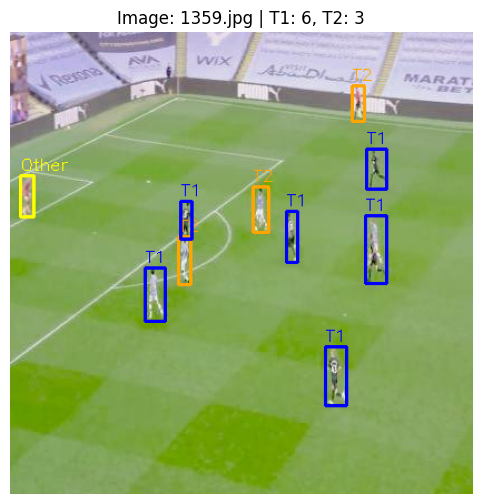

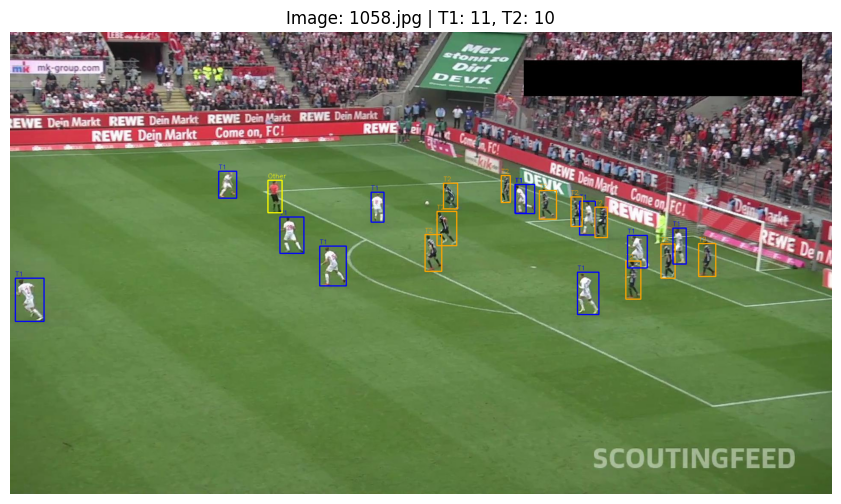

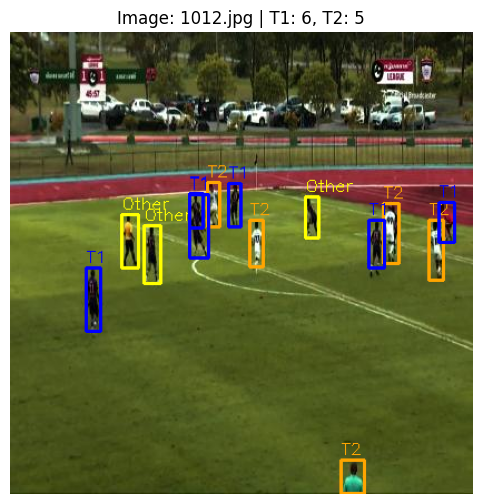

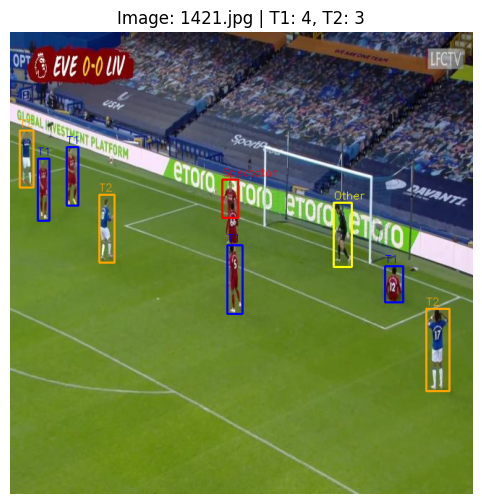

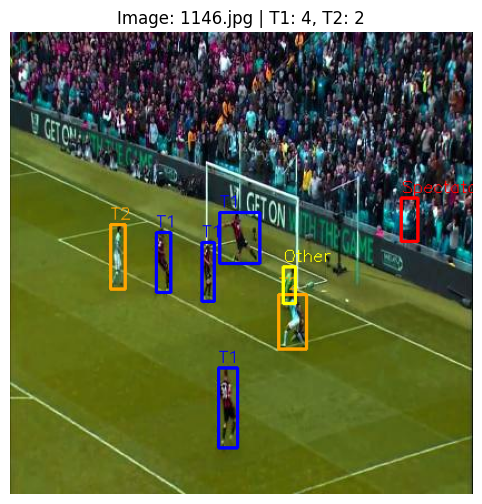

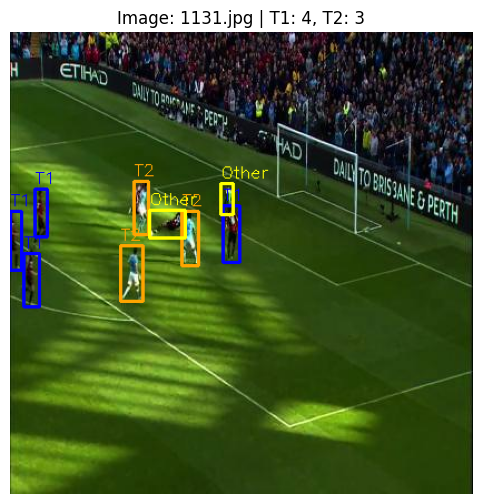

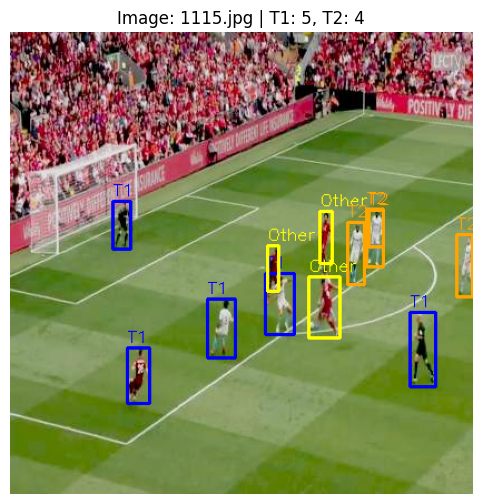

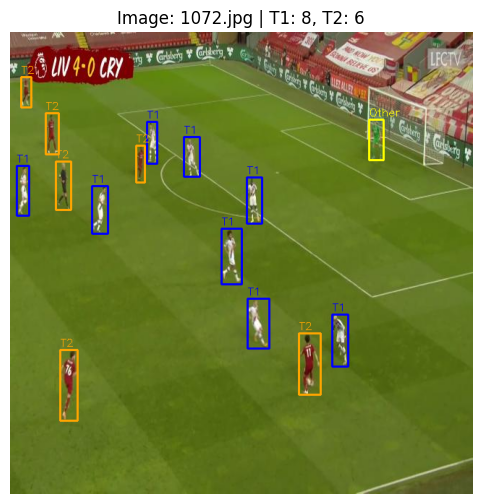

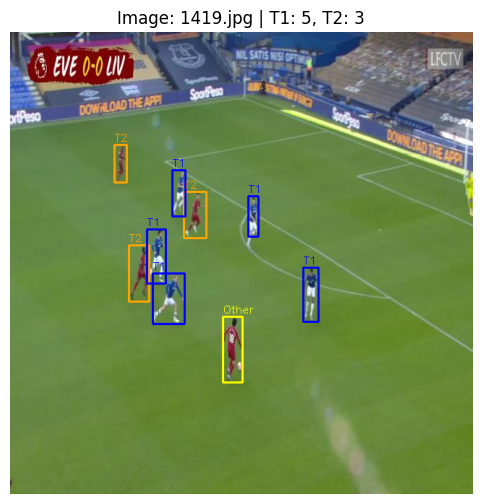

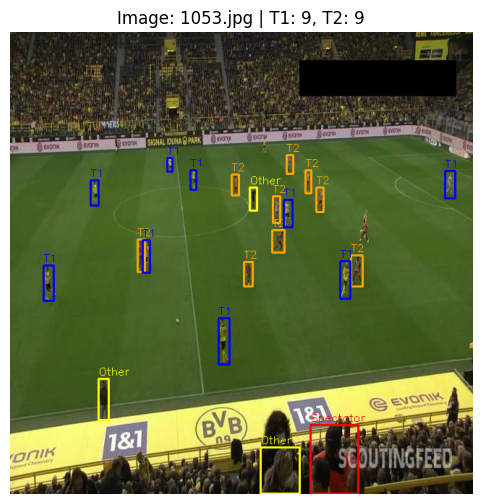

[{'image': '1359.jpg', 'team_1': np.int64(6), 'team_2': np.int64(3)},
 {'image': '1058.jpg', 'team_1': np.int64(11), 'team_2': np.int64(10)},
 {'image': '1012.jpg', 'team_1': np.int64(6), 'team_2': np.int64(5)},
 {'image': '1421.jpg', 'team_1': np.int64(4), 'team_2': np.int64(3)},
 {'image': '1146.jpg', 'team_1': np.int64(4), 'team_2': np.int64(2)},
 {'image': '1131.jpg', 'team_1': np.int64(4), 'team_2': np.int64(3)},
 {'image': '1115.jpg', 'team_1': np.int64(5), 'team_2': np.int64(4)},
 {'image': '1072.jpg', 'team_1': np.int64(8), 'team_2': np.int64(6)},
 {'image': '1419.jpg', 'team_1': np.int64(5), 'team_2': np.int64(3)},
 {'image': '1053.jpg', 'team_1': np.int64(9), 'team_2': np.int64(9)}]

In [ ]:
image_paths = collect_test_images(TEST_DIR)

print(f"Total images found: {len(image_paths)}")

model = YOLO(MODEL_NAME)

df_results = run_random_test_samples(model, image_paths, n = 10)
df_results

In [ ]:
all_images = collect_test_images(TEST_DIR)
if not all_images:
    raise RuntimeError("No images were found in the dataset directory.")

model = YOLO(MODEL_NAME)
model.to(YOLO_DEVICE)

records: list[dict] = []
for image_path in tqdm(all_images, desc="analyze pic"):
    team_a, team_b = analyze_image(image_path, model)
    ordered = sorted((team_a, team_b), reverse=True)
    records.append({
        "image_name": image_path.name,
        "count_1": int(ordered[0]),
        "count_2": int(ordered[1]),
    })

submission = pd.DataFrame(records).sort_values("image_name").reset_index(drop=True)
print(f"Total processed images: {len(submission)}")
submission.head()

analyze pic:   0%|          | 0/465 [00:00<?, ?it/s]

Total processed images: 465


,image_name,count_1,count_2
0,1000.jpg,4,2
1,1001.jpg,7,4
2,1002.jpg,5,5
3,1003.jpg,4,3
4,1004.jpg,7,5


In [ ]:
if not os.path.exists(os.path.join(os.getcwd(), 'notebook.ipynb')):
    %notebook -e notebook.ipynb

def compress(file_names):
    print("File Paths:")
    print(file_names)
    compression = zipfile.ZIP_DEFLATED
    with zipfile.ZipFile("result.zip", mode="w") as zf:
        for file_name in file_names:
            zf.write('./' + file_name, file_name, compress_type=compression)

submission.to_csv('submission.csv', index=False)
file_names = ['notebook.ipynb', 'submission.csv']
compress(file_names)

File Paths:
['notebook.ipynb', 'submission.csv']
